# Block 0 — Imports

In [1]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

import matplotlib.pyplot as plt


# Block 1 — Objective of this Notebook

## 1. Objetivo del notebook

El objetivo de este notebook es entrenar y evaluar distintos modelos de Machine Learning
para la predicción de ventas diarias, utilizando las features temporales y estadísticas
creadas previamente.

Los modelos se evaluarán comparándolos con los baselines definidos en el Notebook 03,
especialmente el baseline estacional (lag 7), que representa un punto de referencia fuerte
en problemas de forecasting retail.


# Block 2 — Load Prepared Dataset

In [7]:
df = pd.read_pickle("../data/processed/demand_forecasting_features.pkl")

df.head()


,date,store,item,sales,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_std_7,rolling_mean_14,rolling_std_14,rolling_mean_28,rolling_std_28,day_of_week,week_of_year,month,year
0,2013-01-29,6,1,6,9.0,3.0,11.0,20.0,7.428571,2.572751,8.214286,2.860300,9.428571,3.414876,1,5,1,2013
1,2013-01-29,8,12,57,48.0,38.0,41.0,54.0,47.571429,7.184640,47.214286,7.747740,48.250000,8.149642,1,5,1,2013
2,2013-01-29,8,49,19,12.0,22.0,10.0,12.0,18.285714,4.151879,17.571429,4.685728,18.500000,5.357584,1,5,1,2013
3,2013-01-29,3,10,47,29.0,42.0,36.0,38.0,46.142857,10.510765,45.214286,9.099269,45.000000,8.485281,1,5,1,2013
4,2013-01-29,10,29,42,40.0,46.0,38.0,35.0,48.714286,5.822780,46.857143,9.670392,44.785714,9.496031,1,5,1,2013


The dataset already contains:
- Sales lags
- Rolling statistics
- Time variables (day, week, month, year)

Therefore, it is ready for modeling.

# Block 3 — Train / Validation Split (Time-based)

In [11]:
split_date = df["date"].quantile(0.8)

train_df = df[df["date"] <= split_date]
val_df = df[df["date"] > split_date]

X_train = train_df.drop(columns=["sales", "date"])
y_train = train_df["sales"]

X_val = val_df.drop(columns=["sales", "date"])
y_val = val_df["sales"]

X_train.shape, X_val.shape


((719500, 16), (179500, 16))

The division is performed respecting the temporal order, avoiding any type of data leakage.

# Block 4 — Linear Regression Model

## 4.1 Model and Pipeline

In [9]:
numeric_features = X_train.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features)
    ]
)

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)


## 4.2 Training

In [10]:
lr_model.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Linear regression serves as a first interpretable and rapid model,
allowing us to evaluate how much the models improve compared to simple baselines.

## 4.3 Evaluation 

In [16]:
y_pred_lr = lr_model.predict(X_val)

mae_lr = mean_absolute_error(y_val, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_val, y_pred_lr))

print(f"Linear Regression MAE: {mae_lr:.2f}")
print(f"Linear Regression RMSE: {rmse_lr:.2f}")


Linear Regression MAE: 6.92
Linear Regression RMSE: 9.05


# Block 5 — Random Forest Regressor

# 5.1 Model Setting

In [18]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)


## 5.2 Training

In [19]:
rf_model.fit(X_train, y_train)


,n_estimators,100
,criterion,'squared_error'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## 5.3 Evaluation model

In [20]:
y_pred_rf = rf_model.predict(X_val)

mae_rf = mean_absolute_error(y_val, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_val, y_pred_rf))

print(f"Random Forest MAE: {mae_rf:.2f}")
print(f"Random Forest RMSE: {rmse_rf:.2f}")


Random Forest MAE: 6.35
Random Forest RMSE: 8.28


Random Forest allows capturing non-linear relationships and
usually performs significantly better than linear models
in forecasting problems with complex seasonality.

# Block 6 — Model Comparison

In [22]:
results = pd.DataFrame({
    "Model": [
        "Seasonal Naive (Lag 7)",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        8.84,       # baseline Notebook 03
        mae_lr,
        mae_rf
    ],
    "RMSE": [
        11.60,      # baseline Notebook 03
        rmse_lr,
        rmse_rf
    ]
})

results


,Model,MAE,RMSE
0,Seasonal Naive (Lag 7),8.840000,11.600000
1,Linear Regression,6.920209,9.046704
2,Random Forest,6.348570,8.276888


## 6.1 Visual Comparison

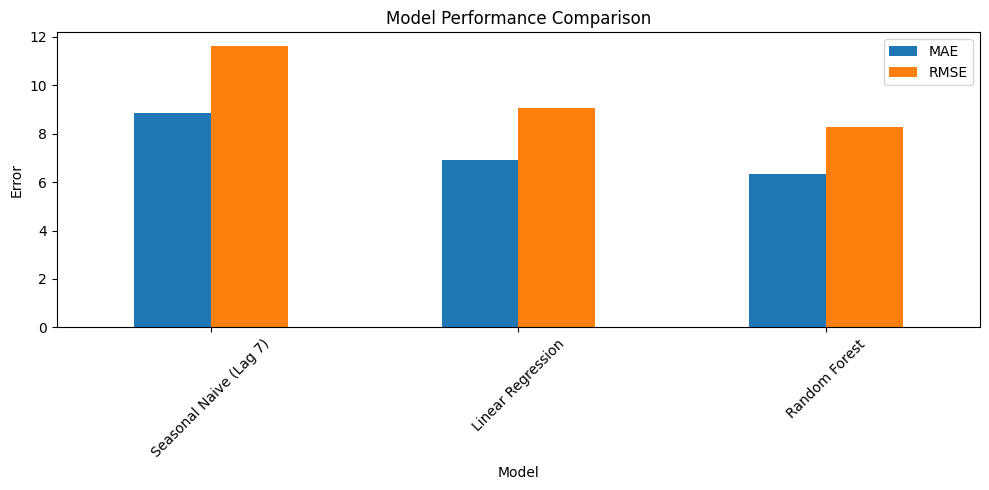

In [23]:
results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Block 7 — Interpretation of Results

- The seasonal baseline (lag 7) establishes a level of error that is difficult to beat.

- Linear regression usually offers a moderate improvement.

- Random Forest typically performs best, capturing nonlinear interactions and complex patterns.

In a real-world environment, any production model should
clearly outperform the seasonal baseline.



# Block 8 — Conclusions and Next Steps

- Classical machine learning models for forecasting have been trained and evaluated.

- Comparison with simple baselines ensures a rigorous approach.

- The results justify the use of more complex models.

Possible next steps:
- Hyperparameter tuning
- Boosting models (LightGBM, XGBoost)
- Multi-step forecasting
- Analysis by store and product